# Detección de cambios con geometría de información
## tl;dr
El método gaussiano debe evaluarse como proyección: detecta media/escala pero pierde cambios de forma. Comparación con KS y Wasserstein y calibración separada.

## Context & Methods
### Key Assumptions
Referencia fija, ventanas de calibración limpias e independientes; una decisión por batch, sin garantía secuencial. Configuración experiments/drift.json. Fórmulas y prior art en informe.md.
### 1. Datos y controles

In [1]:
import json,csv
from pathlib import Path
import numpy as np
from IPython.display import display,Image
from src.drift import scores,calibrate
from src.drift_benchmark import plot
config=json.loads(Path('experiments/drift.json').read_text())
result=json.loads(Path('benchmarks/drift-results.json').read_text())
print(config['question'])
print(result['checks'])
assert all(result['passed'].values())

¿Cuándo la proyección gaussiana Fisher–Rao detecta drift de media/escala y cuándo pierde cambios de forma frente a KS y W1?
{'oracle_error': 8.881784197001252e-16, 'mean_power_n128': 1.0, 'scale_power_n128': 1.0}


## Data
### 2. Recalibración desde semilla y predicción real
La evaluación no participa en el ajuste del umbral.

In [2]:
data=np.load('data/drift-examples.npz')
n=128
rng=np.random.default_rng(config['seed']+n)
reference=rng.normal(size=n)
windows=rng.normal(size=(config['calibration_windows'],n))
np.testing.assert_array_equal(reference,data['reference_128'])
detector=calibrate(reference,windows,config['alpha'],config['calibration_delta'])
values,alarms=detector.predict(data['128_scale_shift_0'])
print('FR,KS,W1 scores:',values,'alarms:',alarms,'thresholds:',detector.thresholds)
# Igualdad de momentos no preserva la ley.
a=np.linspace(-1,1,128);a=(a-a.mean())/a.std()
b=np.tile([-1.,1.],64)
print('Same sample moments, distinct shapes:',scores(a,b))
assert scores(a,b)[0]<1e-12 and scores(a,b)[1]>.1

FR,KS,W1 scores: [0.79640033 0.2109375  0.63880669] alarms: [ True  True  True] thresholds: [0.24818214 0.1484375  0.25550351]
Same sample moments, distinct shapes: [3.12250226e-17 2.89062500e-01 4.43383396e-01]


## Results
### 3. Todas las tasas a n=128
Wilson 95%, condicionado a una referencia/calibración; AR1 viola el supuesto IID.

In [3]:
rows=list(csv.DictReader(Path('benchmarks/drift-summary.csv').open()))
for row in rows:
    if row['n']=='128':
        print(row['scenario'],row['method'],round(float(row['rate']),3),[round(float(row[c]),3) for c in ['lower95','upper95']])

null fr 0.067 [0.044, 0.101]
null ks 0.02 [0.009, 0.043]
null w1 0.03 [0.016, 0.056]
mean_shift fr 1.0 [0.987, 1.0]
mean_shift ks 1.0 [0.987, 1.0]
mean_shift w1 1.0 [0.987, 1.0]
scale_shift fr 1.0 [0.987, 1.0]
scale_shift ks 0.613 [0.557, 0.667]
scale_shift w1 1.0 [0.987, 1.0]
matched_mixture fr 0.01 [0.003, 0.029]
matched_mixture ks 1.0 [0.987, 1.0]
matched_mixture w1 0.997 [0.981, 0.999]
correlated_null fr 0.57 [0.513, 0.625]
correlated_null ks 0.413 [0.359, 0.47]
correlated_null w1 0.403 [0.349, 0.46]


### 4. Figura regenerada desde CSV
El código de dibujo editable vive en src/drift_benchmark.py.

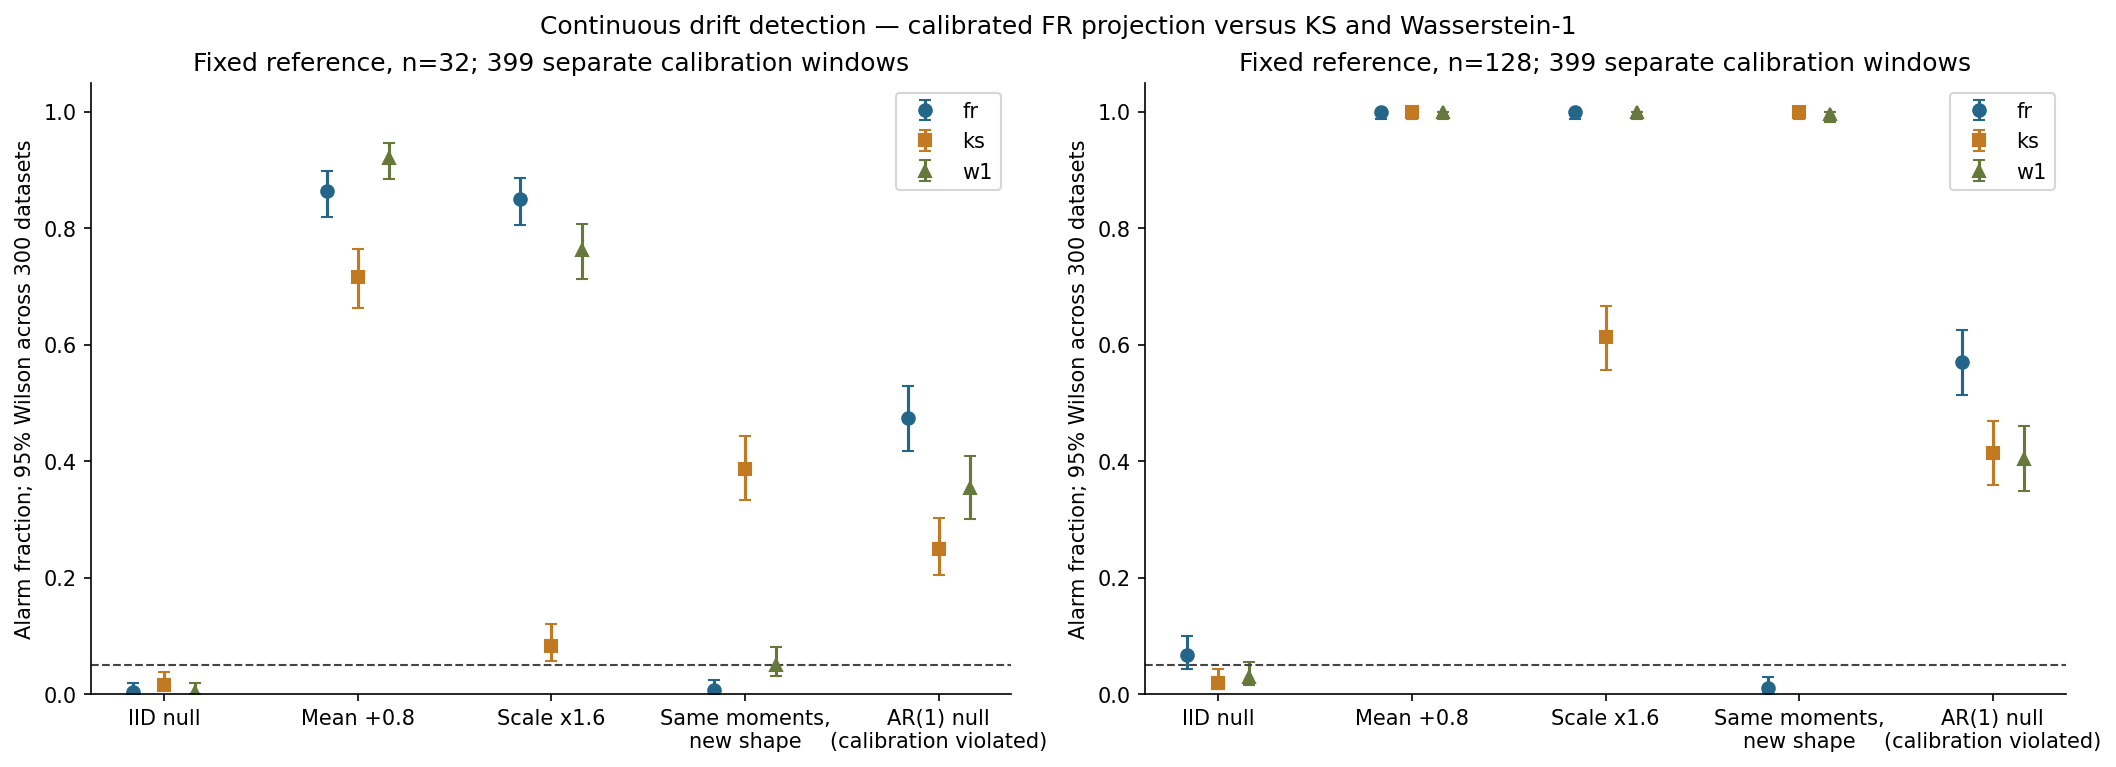

In [4]:
typed=[{**r,'n':int(r['n']),'rate':float(r['rate']),'lower95':float(r['lower95']),'upper95':float(r['upper95'])} for r in rows]
plot(typed)
display(Image(filename='benchmarks/drift.png'))

## Takeaways
No existe superioridad universal. La proyección gaussiana descarta cambios de forma; KS/W1 conservan información distinta. La calibración de rangos incorpora incertidumbre del umbral y se limita al supuesto de ventanas limpias de igual ley. AR1 muestra un fallo importante. El piloto marginal con 9% de falsas alarmas se conserva; esta corrección es exploratoria, no validación externa. Abrir en Jupyter para revisión visual integral; figura revisada por separado.